# Распознавание лиц: классификация знаменитостей (PyTorch + PyTorch Lightning)

**Датасет:** изображения 5 знаменитостей (Bill Gates, Elon Musk, Jeff Bezos, Mark Zuckerberg, Steve Jobs)
в папках `data/train` (по 600 фото на человека) и `data/valid` (по 66-223 фото на человека).

**Структура ноутбука:**
1. **Импорт библиотек** — PyTorch, torchvision, OpenCV.
2. **Загрузка данных** — `ImageFolder`, трансформы (аугментация для обучения, детерминированные
   трансформы для валидации), `DataLoader`.
3. **Модель 1 — ResNet18 (PyTorch Lightning, всё обучается)** — класс `FaceRecognitionModel`
   на базе предобученного ResNet18; обучение через `pl.Trainer`.
4. **Модель 2 — ResNet18 (fine-tuning, замороженный ResNet)** — тот же класс с флагом
   `freeze_resnet=True`: замороженный предобученный ResNet работает как фиксированный
   экстрактор признаков, обучается только новый слой-классификатор.
5. **Модель 3 — ResNet50 (nn.Module, обучение вручную)** — класс `nn.Module` (без Lightning)
   и классический цикл обучения с руками: forward, loss, backward, optimizer.step.
6. **Сравнение моделей** — таблица метрик, сохранение лучшей модели в `.pt`,
   визуализация предсказаний на валидационных данных.
7. **TensorBoard** — запуск в последней ячейке для наблюдения за экспериментами Lightning.


In [1]:
# Ячейка 1. Базовые импорты (стандартные библиотеки и визуализация)
import numpy as np
import random
import matplotlib.pyplot as plt
import os
import time
import glob


In [2]:
# Ячейка 2. PyTorch и torchvision
import torch
import torch.nn as nn
import torchvision
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
import cv2

# Фиксируем случайные зерна (seed), чтобы результаты были воспроизводимы
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("torch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


torch: 2.11.0+cu128
GPU available: True


In [3]:
# Ячейка 3. Проверяем, что модуль torchvision.models доступен
# models - коллекция готовых архитектур (ResNet, VGG, AlexNet и др.)
print("torchvision.models:", dir(models))

torchvision.models: ['AlexNet', 'AlexNet_Weights', 'ConvNeXt', 'ConvNeXt_Base_Weights', 'ConvNeXt_Large_Weights', 'ConvNeXt_Small_Weights', 'ConvNeXt_Tiny_Weights', 'DenseNet', 'DenseNet121_Weights', 'DenseNet161_Weights', 'DenseNet169_Weights', 'DenseNet201_Weights', 'EfficientNet', 'EfficientNet_B0_Weights', 'EfficientNet_B1_Weights', 'EfficientNet_B2_Weights', 'EfficientNet_B3_Weights', 'EfficientNet_B4_Weights', 'EfficientNet_B5_Weights', 'EfficientNet_B6_Weights', 'EfficientNet_B7_Weights', 'EfficientNet_V2_L_Weights', 'EfficientNet_V2_M_Weights', 'EfficientNet_V2_S_Weights', 'GoogLeNet', 'GoogLeNetOutputs', 'GoogLeNet_Weights', 'Inception3', 'InceptionOutputs', 'Inception_V3_Weights', 'MNASNet', 'MNASNet0_5_Weights', 'MNASNet0_75_Weights', 'MNASNet1_0_Weights', 'MNASNet1_3_Weights', 'MaxVit', 'MaxVit_T_Weights', 'MobileNetV2', 'MobileNetV3', 'MobileNet_V2_Weights', 'MobileNet_V3_Large_Weights', 'MobileNet_V3_Small_Weights', 'RegNet', 'RegNet_X_16GF_Weights', 'RegNet_X_1_6GF_Weigh

In [4]:
# Ячейка 4. Шаблон трансформаций (с аугментацией)

data_transforms = transforms.Compose([
        transforms.RandomResizedCrop(256),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation((-30,30)),
        transforms.RandomGrayscale(p=0.3),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])
BATCH_SIZE = 16  # количество изображений в одном батче
EPOCHS = 10      # число эпох для каждой модели (можно уменьшить для быстрой прогонки)


In [5]:

print(os.getcwd())


d:\Skillfactory_local\ML\CV\CV_project1


In [6]:
# Ячейка 6. Загрузка датасетов через ImageFolder

from torchvision.datasets import ImageFolder
celebrity_dataset_train = ImageFolder(os.path.join('data', 'train'))
celebrity_dataset_test = ImageFolder(os.path.join('data', 'valid'))


In [7]:
# Ячейка 7. Проверяем тип объекта датасета
print(type(celebrity_dataset_train))


<class 'torchvision.datasets.folder.ImageFolder'>


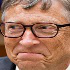

In [8]:
# Ячейка 8. Что внутри первого элемента: вторым идёт номер класса (0, 1, 2, ...)
celebrity_dataset_train[0][0]


In [9]:
# Ячейка 9. По номеру класса получаем его имя
# (список classes ImageFolder отсортирован по алфавиту)
celebrity_dataset_train.classes[celebrity_dataset_train[0][1]]


'bill_gates'

In [10]:
# Ячейка 10. Смотрим исходный код ImageFolder, чтобы понять механику:

import inspect

print(inspect.getsource(ImageFolder))


class ImageFolder(DatasetFolder):
    """A generic data loader where the images are arranged in this way by default: ::

        root/dog/xxx.png
        root/dog/xxy.png
        root/dog/[...]/xxz.png

        root/cat/123.png
        root/cat/nsdf3.png
        root/cat/[...]/asd932_.png

    This class inherits from :class:`~torchvision.datasets.DatasetFolder` so
    the same methods can be overridden to customize the dataset.

    Args:
        root (str or ``pathlib.Path``): Root directory path.
        transform (callable, optional): A function/transform that takes in a PIL image or torch.Tensor, depends on the given loader,
            and returns a transformed version. E.g, ``transforms.RandomCrop``
        target_transform (callable, optional): A function/transform that takes in the
            target and transforms it.
        loader (callable, optional): A function to load an image given its path.
        is_valid_file (callable, optional): A function that takes path of an Im

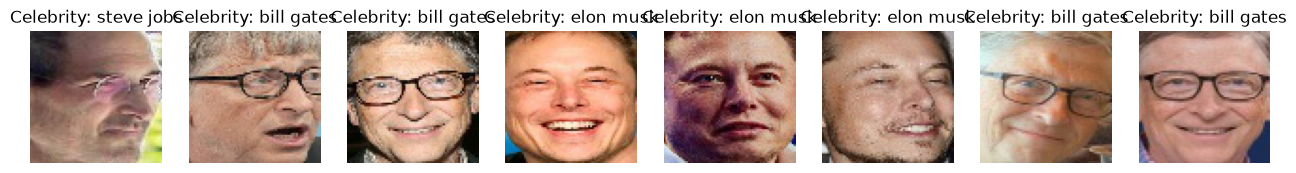

In [11]:
# Ячейка 11. Визуализация: рисуем случайный батч изображений с именами классов

import random
import matplotlib.pyplot as plt

def plot_samples(dataset, num_samples=BATCH_SIZE//2):      # для наглядности рисуем половину батча
    fig, axes = plt.subplots(1, num_samples, figsize=(16, 8))

    for i in range(num_samples):
        random_image, random_class = random.choice(dataset)
        random_label = dataset.classes[random_class]
        axes[i].imshow(random_image)
        axes[i].set_title("Celebrity: " + random_label.replace("_", " "))
        axes[i].axis("off")

    plt.show()

plot_samples(celebrity_dataset_train)


In [12]:
# Ячейка 12. Статистика датасетов: соответствие "номер класса -> имя"
# и количество обучающих/валидационных изображений
print(celebrity_dataset_train.class_to_idx)
print("Number of training samples:", len(celebrity_dataset_train))
print("Number of validation samples:", len(celebrity_dataset_test))


{'bill_gates': 0, 'elon_musk': 1, 'jeff_bezos': 2, 'mark_zuckerberg': 3, 'steve_jobs': 4}
Number of training samples: 3000
Number of validation samples: 914


In [13]:
# Ячейка 13. Назначаем рабочие трансформы датасетам и создаём DataLoaders

celebrity_dataset_train.transform = transforms.Compose([
        transforms.RandomResizedCrop(256, scale=(0.5, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])
# ВАЖНО для лиц: у RandomResizedCrop задан scale=(0.5, 1.0) - кроп не меньше
# половины площади кадра. Дефолтный scale=(0.08, 1.0) может вырезать крошечный
# кусок (лоб, ухо, фон) и растянуть его - модель училась бы на мусоре,
# ведь лицо - единственный важный признак в нашей задаче.

celebrity_dataset_test.transform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(256),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])
data_loader_train = DataLoader(celebrity_dataset_train, batch_size=BATCH_SIZE, shuffle=True)
data_loader_test = DataLoader(celebrity_dataset_test, batch_size=BATCH_SIZE, shuffle=False)


# Часть I. Обучаем модель на датасете с изображениями знаменитостей (PyTorch Lightning, ResNet18)


In [14]:
# Создаем класс LightningModule для обучения модели с использованием PyTorch Lightning.

import pytorch_lightning as pl

class FaceRecognitionModel(pl.LightningModule):
    def __init__(self, num_classes, freeze_resnet=False):
        super(FaceRecognitionModel, self).__init__()
        self.model = models.resnet18(pretrained=True)  # предобученные веса ResNet18
        self.model.fc = nn.Linear(self.model.fc.in_features, num_classes)  # наша "голова"
        self.criterion = nn.CrossEntropyLoss()
        self.freeze_resnet = freeze_resnet

        if freeze_resnet:
            
            for param in self.model.parameters():
                param.requires_grad = False
            for param in self.model.fc.parameters():
                param.requires_grad = True

    def unfreeze_last_block(self):
        """Gradual unfreezing: размораживает последний блок ResNet (layer4).

        Вызываем ПОСЛЕ того, как "голова" fc уже немного обучилась:
        к этому моменту градиенты от неё выровнялись, и глубокие слои
        можно аккуратно подправить маленьким lr (задаётся в configure_optimizers).
        """
        for param in self.model.layer4.parameters():
            param.requires_grad = True

    def forward(self, x):
        # Прямой проход: x - батч тензоров [B, 3, 256, 256] -> логиты [B, num_classes]
        return self.model(x)

    def training_step(self, batch, batch_idx):
        images, labels = batch
        outputs = self(images)
        loss = self.criterion(outputs, labels)
        acc = (outputs.argmax(dim=1) == labels).float().mean()
        self.log('train_loss', loss)   # логируется в TensorBoard (lightning_logs/)
        self.log('train_acc', acc)
        return loss

    def validation_step(self, batch, batch_idx):
        images, labels = batch
        outputs = self(images)
        loss = self.criterion(outputs, labels)
        acc = (outputs.argmax(dim=1) == labels).float().mean()
        self.log('val_loss', loss)
        self.log('val_acc', acc)

    def configure_optimizers(self):
        # РАЗДЕЛЬНЫЕ learning rates для "головы" и "тела":
        #  - голова fc обучается С НУЛЯ (случайная инициализация) -> ей нужен
        #    крупный шаг lr=1e-3, иначе за 10 эпох она не успеет обучиться;
        #  - предобученные слои (если разморожены) -> аккуратный lr=1e-4,
        #    чтобы не "сломать" полезные веса ImageNet.
        # В оптимизатор передаем ТОЛЬКО обучаемые параметры (p.requires_grad):
        # так Adam не тратит память на состояния для замороженных весов.
        head = list(self.model.fc.parameters())
        body = [p for n, p in self.model.named_parameters()
                if not n.startswith('fc') and p.requires_grad]
        param_groups = [{'params': head, 'lr': 1e-3}]
        if body:
            param_groups.append({'params': body, 'lr': 1e-4})
        optimizer = torch.optim.Adam(param_groups)
        return optimizer


W1008 12:24:53.933000 24108 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


In [15]:
# Определяем устройство: если есть GPU (CUDA) - считаем на нём, иначе на CPU.
# Все модели и данные в дальнейшем переносим на это устройство с помощью .to(device).
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Используемое устройство:", device)


Используемое устройство: cuda


In [16]:
# Создаем экземпляр модели (ВЕРСИЯ 1: полная донастройка, ResNet18 НЕ заморожен) и тренируем ее.
# num_classes берем из датасета: сколько подпапок в data/train, столько и классов.
num_classes = len(celebrity_dataset_train.classes)
print("Классы датасета:", celebrity_dataset_train.classes)
print("Количество классов:", num_classes)

model = FaceRecognitionModel(num_classes=num_classes, freeze_resnet=False)

# Считаем, сколько параметров модели будет обучаться (всего и с учётом requires_grad)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Всего параметров:     {:,}".format(total_params))
print("Обучаемых параметров:  {:,}".format(trainable_params))
print(model)


c:\Users\user\miniconda3\envs\cv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\user\miniconda3\envs\cv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Классы датасета: ['bill_gates', 'elon_musk', 'jeff_bezos', 'mark_zuckerberg', 'steve_jobs']
Количество классов: 5
Всего параметров:     11,179,077
Обучаемых параметров:  11,179,077
FaceRecognitionModel(
  (model): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    

In [17]:
# Запускаем обучение с помощью PyTorch Lightning (модель 1: ResNet18, всё обучается).
# pl.Trainer сам управляет циклами train/val, переносом на device,
# логированием в TensorBoard и сохранением checkpoints (папка lightning_logs/).
trainer = pl.Trainer(max_epochs=EPOCHS)
trainer.fit(model, data_loader_train, data_loader_test)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
You are using a CUDA device ('NVIDIA GeForce RTX 5060 Ti') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type             | Params | Mode  | FLOPs
-----------------

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

c:\Users\user\miniconda3\envs\cv\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\user\miniconda3\envs\cv\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
c:\Users\user\miniconda3\envs\cv\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=10` reached.


# Часть II. Fine-tuning: ResNet18 с замороженным ResNet (учим только слой-классификатор)

Идея **тонкой настройки (fine-tuning)**: веса предобученного на ImageNet ResNet уже умеют
извлекать полезные для распознавания лиц признаки. Замораживаем их (требуя градиенты только
для нового слоя-классификатора), чтобы:
- обучить модель на нашем (небольшом) датасете быстрее;
- не «затащить» (не перетренировать) полезные предобученные веса.


In [18]:
# MODEL 2. Fine-tuning: создаем модель с ЗАМОРОЖЕННЫМ ResNet18 (freeze_resnet=True).
# Теперь в обучении участвует только новый слой-классификатор fc.
model_frozen = FaceRecognitionModel(num_classes=num_classes, freeze_resnet=True)

# Проверяем, что заморозка сработала: обучаемых параметров должно быть на порядки меньше
# (это всего весовой слой fc: 512 входных признаков * 5 классов + bias)
trainable_frozen = sum(p.numel() for p in model_frozen.parameters() if p.requires_grad)
total_frozen = sum(p.numel() for p in model_frozen.parameters())
print("Модель 2 (замороженный ResNet18):")
print("  Всего параметров:     {:,}".format(total_frozen))
print("  Обучаемых параметров:  {:,}".format(trainable_frozen))


Модель 2 (замороженный ResNet18):
  Всего параметров:     11,179,077
  Обучаемых параметров:  2,565


In [19]:
# Обучаем вторую модель (замороженный ResNet18) через тот же Trainer.
trainer2 = pl.Trainer(max_epochs=EPOCHS)
trainer2.fit(model_frozen, data_loader_train, data_loader_test)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type             | Params | Mode  | FLOPs
---------------------------------------------------------------
0 | model     | ResNet           | 11.2 M | train | 0    
1 | criterion | CrossEntropyLoss | 0      | train | 0    
---------------------------------------------------------------
2.6 K     Trainable params
11.2 M    Non-trainable params
11.2 M    Total params
44.716    Total estimated model params size (MB)
69        

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=10` reached.


## Часть II-б. Gradual unfreezing: дообучаем модель 2, открыв последний блок ResNet

Стратегия «постепенной разморозки»: сначала обучили только «голову» (сделано выше),
теперь размораживаем `layer4` — самый «смысловой» блок ResNet, где формируются
признаки уровня «форма лица», а не просто «края и текстуры». Это промежуточный
вариант между моделями 1 и 2 и часто даёт лучший результат, чем обе.


In [20]:
# Gradual unfreezing: "голова" модели 2 уже обучилась (прошлый fit),
# теперь размораживаем последний блок layer4 и дообучаем еще EPOCHS эпох.

model_frozen.unfreeze_last_block()

trainable_unfrozen = sum(p.numel() for p in model_frozen.parameters() if p.requires_grad)
print("Модель 2 после unfreeze layer4:")
print("  Обучаемых параметров:  {:,}".format(trainable_unfrozen))

# Новый Trainer -> configure_optimizers вызовется заново и подхватит
# размороженные параметры (группа body с lr=1e-4)
trainer3 = pl.Trainer(max_epochs=EPOCHS)
trainer3.fit(model_frozen, data_loader_train, data_loader_test)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type             | Params | Mode  | FLOPs
---------------------------------------------------------------
0 | model     | ResNet           | 11.2 M | train | 0    
1 | criterion | CrossEntropyLoss | 0      | train | 0    
---------------------------------------------------------------
8.4 M     Trainable params
2.8 M     Non-trainable params
11.2 M    Total params
44.716    Total estimated model params size (MB)
69        

Модель 2 после unfreeze layer4:
  Обучаемых параметров:  8,396,293


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=10` reached.


# Часть III. ResNet50 как чистый nn.Module: обучение вручную, без Lightning

По той же задаче, но:
- архитектура — предобученный **ResNet50** (глубже, тяжелее, признаков больше);
- модель — обычный класс **`nn.Module`** (без PyTorch Lightning);
- цикл обучения пишется **вручную**: forward, loss, `backward`, `optimizer.step`,
  плюс счётчики loss/accuracy для фаз train/val — как в классическом сценарии.


In [21]:
# MODEL 3. Пишем класс модели руками на nn.Module (без PyTorch Lightning).

class FaceRecognitionResNet50(nn.Module):
    def __init__(self, num_classes):
        super(FaceRecognitionResNet50, self).__init__()

        # Берем предобученный ResNet50 (глубже ResNet18: 50 весовых слоёв).
        self.model = models.resnet50(pretrained=True)

        # Сколько нейронов подается на вход выходному слою классификатора
        n_neurons = self.model.fc.in_features
        print("Входной размер исходного слоя-классификатора ResNet50:", n_neurons)

        # Заменим этот слой на новый: выходное количество нейронов
        self.model.fc = nn.Linear(n_neurons, num_classes)

        # Замо́рожим ВСЕ предобученные слои сети (веса ResNet50 не обновляются)
        for param in self.model.parameters():
            param.requires_grad = False

        # Включим обучение ТОЛЬКО добавленному выходному слою классификатора
        for param in self.model.fc.parameters():
            param.requires_grad = True

    def forward(self, x):
        # Прямой проход: батч [B, 3, 256, 256] -> логиты [B, num_classes]
        return self.model(x)


In [22]:
# Создаем экземпляр модели 3 и переносим ее на device.
model_rn50 = FaceRecognitionResNet50(num_classes=num_classes)
model_rn50 = model_rn50.to(device)

# Сколько параметров реально обучается - только слой fc
trainable_rn50 = sum(p.numel() for p in model_rn50.parameters() if p.requires_grad)
total_rn50 = sum(p.numel() for p in model_rn50.parameters())
print("Модель 3 (ResNet50, замороженный ResNet):")
print("  Всего параметров:     {:,}".format(total_rn50))
print("  Обучаемых параметров:  {:,}".format(trainable_rn50))

# Критерий потерь и оптимизатор.
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_rn50.model.fc.parameters(), lr=1e-3)


c:\Users\user\miniconda3\envs\cv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Входной размер исходного слоя-классификатора ResNet50: 2048
Модель 3 (ResNet50, замороженный ResNet):
  Всего параметров:     23,518,277
  Обучаемых параметров:  10,245


In [23]:
# Обучающий цикл (вручную, без PyTorch Lightning). Внутри цикла:
#  - model.train() / model.eval() - переключение режимов обучения/валидации (BN/Dropout ведут себя по-разному);
#  - torch.set_grad_enabled(phase == 'train') - включение/выключение автоматического дифференцирования
dataloaders = {'train': data_loader_train,
               'val': data_loader_test}


def train_model(model, device, dataloaders, criterion, optimizer,
                batch_size, num_epochs=10):
    """Обучает модель вручную: проходится по эпохам, внутри каждой
    считает loss/acc в фазах 'train' и 'val'. Возвращает обученную модель."""
    since = time.time()

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)

        # На каждой эпохе сначала происходит обучение, затем валидация
        for phase in ['train', 'val']:
            # model.train() - включает режим обучения (BN/Dropout работают "в обучении"),
            # model.eval()  - режим оценки (BN использует накопленную статистику)
            if phase == 'train':
                model.train()
            else:
                model.eval()

            current_loss = 0.0
            current_corrects = 0.0
            batch = 0

            # Проходим по данным соответствующей фазы
            # (валидация целиком идет внутри torch.no_grad() -
            #  градиенты не считаем, это быстрее и экономит память)
            with torch.no_grad():
                for inputs, labels in dataloaders[phase]:
                    batch += 1
                    inputs = inputs.to(device)
                    labels = labels.to(device)

                    # Перед каждым шагом обучения обнуляем градиенты
                    optimizer.zero_grad()

                    # Градиенты считаем только в фазе обучения:
                    # в фазе 'val' автоматическое дифференцирование выключено
                    with torch.set_grad_enabled(phase == 'train'):
                        # Получаем прогноз модели и считаем лосс
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)

                        loss = criterion(outputs, labels)

                        # Обратное распространение и шаг оптимизатора
                        # выполняем ТОЛЬКО в фазе обучения
                        if phase == 'train':
                            loss.backward()
                            optimizer.step()

                    # Считаем накопленные статистики (умножаем на размер батча,
                    # чтобы в конце можно было просто поделить на общее число образцов)
                    current_loss += loss.item() * inputs.size(0)
                    current_corrects += torch.sum(preds == labels).double()

                    # Посмотрим на статистики на каждых 10 батчах (только в обучении)
                    if batch % 10 == 0 and phase == 'train':
                        print("Batch {}, Train Loss:{:.4f}, Train ACC:{:.4f}".format(
                            batch,
                            current_loss / (batch_size * batch),
                            100 * current_corrects / (batch_size * batch)))

            # Итоговые метрики по всей фазе (делим на общее число образцов)
            epoch_loss = current_loss / len(dataloaders[phase].dataset)
            epoch_acc = current_corrects / len(dataloaders[phase].dataset)

            print('{} Loss: {:.4f}  Acc: {:.4f}'.format(phase, epoch_loss, epoch_acc))

    time_elapsed = time.time() - since
    print('Время обучения: {:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
    return model


In [24]:
# Запускаем обучение модели 3 (ResNet50, nn.Module) вручную.
model_rn50 = train_model(
    model_rn50,
    device,
    dataloaders,
    criterion,
    optimizer,
    batch_size=BATCH_SIZE,
    num_epochs=EPOCHS
)


Epoch 0/9
----------
Batch 10, Train Loss:1.6922, Train ACC:23.7500
Batch 20, Train Loss:1.5986, Train ACC:31.2500
Batch 30, Train Loss:1.5283, Train ACC:35.4167
Batch 40, Train Loss:1.4978, Train ACC:36.0938
Batch 50, Train Loss:1.4567, Train ACC:39.1250
Batch 60, Train Loss:1.4057, Train ACC:42.3958
Batch 70, Train Loss:1.3766, Train ACC:44.1964
Batch 80, Train Loss:1.3435, Train ACC:45.9375
Batch 90, Train Loss:1.3190, Train ACC:46.3889
Batch 100, Train Loss:1.2938, Train ACC:47.5625
Batch 110, Train Loss:1.2667, Train ACC:49.0909
Batch 120, Train Loss:1.2517, Train ACC:49.5312
Batch 130, Train Loss:1.2325, Train ACC:50.2885
Batch 140, Train Loss:1.2278, Train ACC:50.6696
Batch 150, Train Loss:1.2076, Train ACC:51.7917
Batch 160, Train Loss:1.1919, Train ACC:52.5000
Batch 170, Train Loss:1.1783, Train ACC:53.1618
Batch 180, Train Loss:1.1635, Train ACC:53.6806
train Loss: 1.1534  Acc: 0.5410
val Loss: 0.8876  Acc: 0.6411
Epoch 1/9
----------
Batch 10, Train Loss:1.0048, Train ACC:61

# Часть IV. Сравнение трёх моделей, сохранение лучшей и визуализация результатов


In [25]:
# Сравниваем все три обученные модели на валидационной выборке.
# evaluate() переключает модель в режим eval(), прогоняет валидацию
# без градиентов (torch.no_grad) и считает:
#   - loss - средний CrossEntropyLoss по всем валидационным изображениям;
#   - acc  - доля изображений, которые классифицированы верно.
# LightningModule и nn.Module здесь универсальны: у обоих вызов
# model(изображения) выполнен через forward().

def evaluate(module, loader, device, criterion):
    module.to(device)        # веса на то же устройство, что и данные
    module.eval()
    total_loss = 0.0
    total_correct = 0
    total_images = 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = module(images)
            total_loss += criterion(outputs, labels).item() * images.size(0)
            total_correct += (outputs.argmax(dim=1) == labels).sum().item()
            total_images += images.size(0)
    return total_loss / total_images, total_correct / total_images

# 'module' - объект для предсказания (LightningModule или nn.Module),
# 'net'    - сама нейросеть, из которой можно сохранить state_dict
models_eval = [
    {'name': 'Model 1: ResNet18, Lightning, полная донастройка',
     'module': model, 'net': model.model},
    {'name': 'Model 2: ResNet18, Lightning, frozen ResNet',
     'module': model_frozen, 'net': model_frozen.model},
    {'name': 'Model 3: ResNet50, nn.Module, frozen ResNet',
     'module': model_rn50, 'net': model_rn50},
]

results = {}
print("=" * 72)
print("Сводка результатов на валидационной выборке")
print("=" * 72)
for m in models_eval:
    loss, acc = evaluate(m['module'], data_loader_test, device, criterion)
    results[m['name']] = (loss, acc)
    print("{:<50} loss: {:6.4f}    acc: {:6.2%}".format(m['name'], loss, acc))

best = max(models_eval, key=lambda m: results[m['name']][1])
print("-" * 72)
print("Лучшая модель по val acc: {}".format(best['name']))


Сводка результатов на валидационной выборке
Model 1: ResNet18, Lightning, полная донастройка   loss: 0.0248    acc: 99.45%
Model 2: ResNet18, Lightning, frozen ResNet        loss: 0.0493    acc: 98.80%
Model 3: ResNet50, nn.Module, frozen ResNet        loss: 0.4434    acc: 84.68%
------------------------------------------------------------------------
Лучшая модель по val acc: Model 1: ResNet18, Lightning, полная донастройка


In [26]:
# Сохраняем лучшую модель (определена в ячейке выше, переменная `best`).
# Сохраняем веса самой нейросети (net.state_dict()).
save_path = 'best_model.pt'
torch.save(best['net'].state_dict(), save_path)
print("Сохранены веса лучшей модели в файл:", os.path.abspath(save_path))
print("Размер файла: {:,.0f} KB".format(os.path.getsize(save_path) / 1024))



Сохранены веса лучшей модели в файл: d:\Skillfactory_local\ML\CV\CV_project1\best_model.pt
Размер файла: 43,746 KB


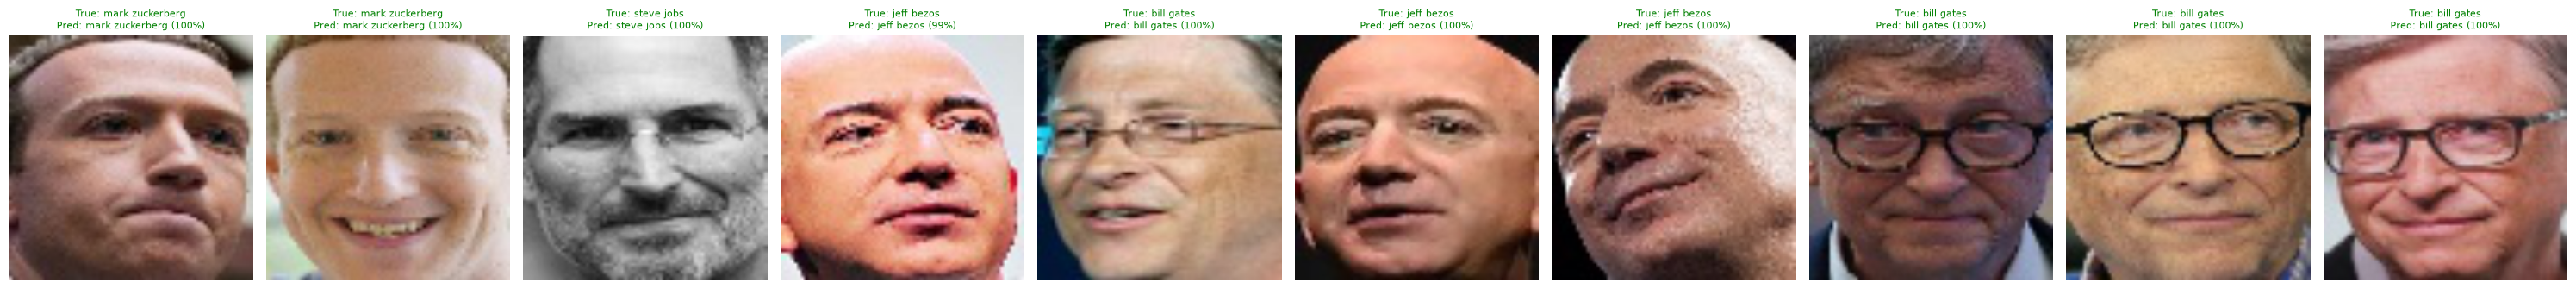

In [27]:
# Визуализируем предсказания лучшей модели на валидационных данных.
# Для каждого изображения смотрим: истинный класс, предсказанный класс
# и уверенность модели (softmax-вероятность предсказанного класса).
# Заголовок зеленый - если модель угадала, красный - если ошиблась.

# Денормализация: модель видела изображения в норме ImageNet (Normalize),
# чтобы нарисовать их, надо вернуть каналы в диапазон [0, 1]
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def denormalize(img_tensor):
    img = img_tensor * STD + MEAN            # обратно из нормы ImageNet
    img = img.clamp(0, 1)                    # обрезаем хвосты за [0, 1]
    return img.permute(1, 2, 0).cpu().numpy()  # CHW -> HWC для matplotlib

num_show = 10
best_module = best['module']
best_module.eval()

# Ровно num_show случайных изображений из валидационного датасета
idxs = random.sample(range(len(celebrity_dataset_test)), num_show)

fig, axes = plt.subplots(1, num_show, figsize=(3 * num_show, 4))
with torch.no_grad():
    for col, idx in enumerate(idxs):
        image, label = celebrity_dataset_test[idx]
        outputs = best_module(image.unsqueeze(0).to(device))   # [1] -> [1, num_classes]
        probs = torch.softmax(outputs, dim=1)[0]               # вероятности классов
        pred = int(outputs.argmax(dim=1))
        true_name = celebrity_dataset_test.classes[int(label)].replace('_', ' ')
        pred_name = celebrity_dataset_test.classes[pred].replace('_', ' ')
        axes[col].imshow(denormalize(image))
        axes[col].set_title("True: {}\nPred: {} ({:.0f}%)".format(
                                true_name, pred_name, 100 * probs[pred].item()),
                            fontsize=8,
                            color='green' if pred == int(label) else 'red')
        axes[col].axis('off')
plt.tight_layout()
plt.show()


## Итоги

В ноутбуке обучено три модели на задаче распознавания знаменитостей:

| Модель | Архитектура | Подход |
|--------|-------------|--------|
| 1 | ResNet18 | PyTorch Lightning, обучается вся сеть (голова lr=1e-3, спина lr=1e-4) |
| 2 | ResNet18 | PyTorch Lightning, fine-tuning в 2 этапа: сначала только fc (lr=1e-3), затем gradual unfreezing layer4 (lr=1e-4) |
| 3 | ResNet50 | чистый `nn.Module`, цикл обучения вручную, ResNet заморожен, fc с lr=1e-3 |

**Куда смотреть результаты:**
- таблица метрик — в ячейке "Сводка результатов на валидационной выборке";
- `lightning_logs/version_N` — эксперименты Lightning-моделей для TensorBoard
  (модель 3 обучалась вне Lightning, её графиков там нет);
- `best_model.pt` — веса лучшей модели, готовые к использованию для инференса.


In [28]:
# TensorBoard: веб-интерфейс для просмотра процесса обучения моделей Lightning.
# Запускается на локальном порту 6006 - после старта откройте в браузере
# http://localhost:6006 (страница с адресом появится в выводе ячейки).

#%load_ext tensorboard
!tensorboard --logdir lightning_logs


"tensorboard" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.
